# Dense Passage Retrieval on FiQA

Install the packages and import what the notebook uses.

In [10]:
%pip install -q -r requirements.txt matplotlib

import json
import torch
import pandas as pd
import matplotlib.pyplot as plt
from omegaconf import OmegaConf
from src.data_utils.corpus import Corpus
from src.data_utils.query import Query
from src.data_utils.dataloader import tokenize, tokenizer
from src.retrievers.base_retriever import Retriever
from src.retrievers.tf_idf import TFIDF
from src.retrievers.bm25 import BM25
from src.retrievers.models.encoder import TransformerEncoder
from src.retrievers.utils import retrieveQueryAndGetRelevancies
from src.evaluation.metrics import Evaluate

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Run main.py, which trains DPR and saves the weights in outputs/weights. Skip this cell if the weights are already copied from the server.

In [ ]:
!python main.py

Load FiQA and make the queries, the same way as in main.py.

In [11]:
corpus = Corpus(dataset_name='fiqa', base_dir='./retrieval_data')

train_queries = [Query(corpus.train['question'][idx],
                       id=corpus.train['query_id'][idx],
                       relevant_document_ids=corpus.relevant_ids[corpus.train['query_id'][idx]])
                 for idx in range(corpus.train.num_rows)]

val_queries = [Query(corpus.val['question'][idx],
                     id=corpus.val['query_id'][idx],
                     relevant_document_ids=corpus.relevant_ids[corpus.val['query_id'][idx]])
               for idx in range(corpus.val.num_rows)]

test_queries = [Query(corpus.test['question'][idx],
                      id=corpus.test['query_id'][idx],
                      relevant_document_ids=corpus.relevant_ids[corpus.test['query_id'][idx]])
                for idx in range(corpus.test.num_rows)]

TF-IDF, the same way as in main.py.

In [12]:
tf_idf = TFIDF(documents=corpus.all_documents)

tfidf_train_relevancies = retrieveQueryAndGetRelevancies(tf_idf, train_queries, k=10)
tfidf_val_relevancies = retrieveQueryAndGetRelevancies(tf_idf, val_queries, k=10)
tfidf_test_relevancies = retrieveQueryAndGetRelevancies(tf_idf, test_queries, k=10)

tfidf_train_scores = Evaluate(tfidf_train_relevancies, train_queries)
tfidf_val_scores = Evaluate(tfidf_val_relevancies, val_queries)
tfidf_test_scores = Evaluate(tfidf_test_relevancies, test_queries)

print(f'TF-IDF Train results: {tfidf_train_scores}')
print(f'TF-IDF Val results: {tfidf_val_scores}')
print(f'TF-IDF Test results: {tfidf_test_scores}')

TF-IDF Train results: {'recall': 0.17444992784992822, 'precision': 0.038709090909089916, 'mrr': 0.15738686868686902}
TF-IDF Val results: {'recall': 0.17378730158730155, 'precision': 0.03900000000000001, 'mrr': 0.16472857142857147}
TF-IDF Test results: {'recall': 0.16391950813247105, 'precision': 0.04182098765432108, 'mrr': 0.1579401822457379}


BM25, the same way as in main.py.

In [13]:
bm25 = BM25(documents=corpus.all_documents)

bm25_train_relevancies = retrieveQueryAndGetRelevancies(bm25, train_queries, k=10)
bm25_val_relevancies = retrieveQueryAndGetRelevancies(bm25, val_queries, k=10)
bm25_test_relevancies = retrieveQueryAndGetRelevancies(bm25, test_queries, k=10)

bm25_train_scores = Evaluate(bm25_train_relevancies, train_queries)
bm25_val_scores = Evaluate(bm25_val_relevancies, val_queries)
bm25_test_scores = Evaluate(bm25_test_relevancies, test_queries)

print(f'BM25 Train results: {bm25_train_scores}')
print(f'BM25 Val results: {bm25_val_scores}')
print(f'BM25 Test results: {bm25_test_scores}')

BM25 Train results: {'recall': 0.33157150072150066, 'precision': 0.07334545454545653, 'mrr': 0.333357792207791}
BM25 Val results: {'recall': 0.33229206349206364, 'precision': 0.07160000000000029, 'mrr': 0.3416515873015872}
BM25 Test results: {'recall': 0.3436954977464237, 'precision': 0.0779320987654325, 'mrr': 0.348077723887909}


DPR with the saved weights, one model for each pooling type

In [14]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
m = OmegaConf.load('config/model/encoder.yaml')

# One trained model for each pooling type, and the folder with its weights
models = {'cls': 'outputs/weights_cls_b32', 'mean': 'outputs/weights_mean_b32', 'max': 'outputs/weights_max_b32'}

def load_encoder(path, pooling):
    encoder = TransformerEncoder(m.n_layers, m.n_heads, m.emb_dim, m.hidden_dim, m.feed_forward_dim, pooling)
    encoder.load_state_dict(torch.load(path, map_location=device))
    return encoder.to(device).eval()

@torch.no_grad()
def encode(encoder, texts, max_length):
    return torch.cat([encoder(tokenize(texts[i:i + 256], max_length).to(device)) for i in range(0, len(texts), 256)])

class DPR(Retriever):
    def __init__(self, documents, folder, pooling):
        super().__init__(documents)
        self.query_encoder = load_encoder(f'{folder}/query_encoder.pt', pooling)
        self.document_encoder = load_encoder(f'{folder}/document_encoder.pt', pooling)
        self.document_vectors = encode(self.document_encoder, [d.GetText() for d in self.index.GetDocuments()], 256)

    def CalculateScores(self, queries):
        return (encode(self.query_encoder, queries, 64) @ self.document_vectors.T).cpu().numpy()

dpr, dpr_val_scores, dpr_test_scores = {}, {}, {}
for pooling, folder in models.items():
    dpr[pooling] = DPR(corpus.all_documents, folder, pooling)
    dpr_val_scores[pooling] = Evaluate(retrieveQueryAndGetRelevancies(dpr[pooling], val_queries, k=10), val_queries)
    dpr_test_scores[pooling] = Evaluate(retrieveQueryAndGetRelevancies(dpr[pooling], test_queries, k=10), test_queries)
    print(f'DPR {pooling} Val results: {dpr_val_scores[pooling]}')
    print(f'DPR {pooling} Test results: {dpr_test_scores[pooling]}')

DPR cls Val results: {'recall': 0.04899126984126984, 'precision': 0.01199999999999999, 'mrr': 0.039565873015873006}
DPR cls Test results: {'recall': 0.04651859200470311, 'precision': 0.01080246913580246, 'mrr': 0.03680861747991377}
DPR mean Val results: {'recall': 0.051107936507936505, 'precision': 0.011599999999999994, 'mrr': 0.039703174603174594}
DPR mean Test results: {'recall': 0.05742455418381345, 'precision': 0.012191358024691346, 'mrr': 0.04477390750538899}
DPR max Val results: {'recall': 0.017804761904761903, 'precision': 0.0056000000000000025, 'mrr': 0.01807698412698413}
DPR max Test results: {'recall': 0.020832720948461687, 'precision': 0.0055555555555555575, 'mrr': 0.013588820301783261}


Results table for the report, all methods on the test queries.

In [15]:
results = {'TF-IDF': tfidf_test_scores, 'BM25': bm25_test_scores}
for pooling in models:
    results[f'DPR ({pooling})'] = dpr_test_scores[pooling]

pd.DataFrame(results).T.round(3)

,recall,precision,mrr
TF-IDF,0.164,0.042,0.158
BM25,0.344,0.078,0.348
DPR (cls),0.047,0.011,0.037
DPR (mean),0.057,0.012,0.045
DPR (max),0.021,0.006,0.014


Training and validation loss per epoch for each pooling type

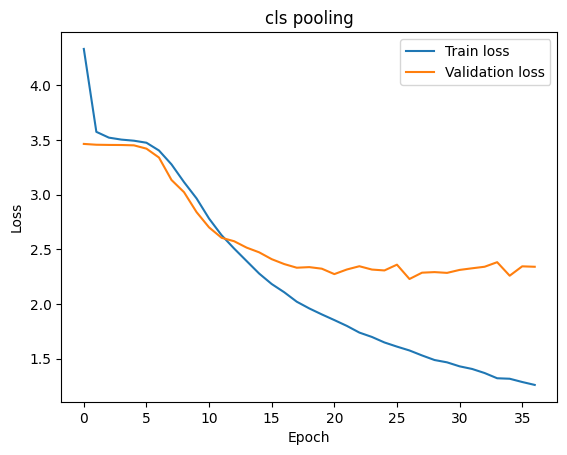

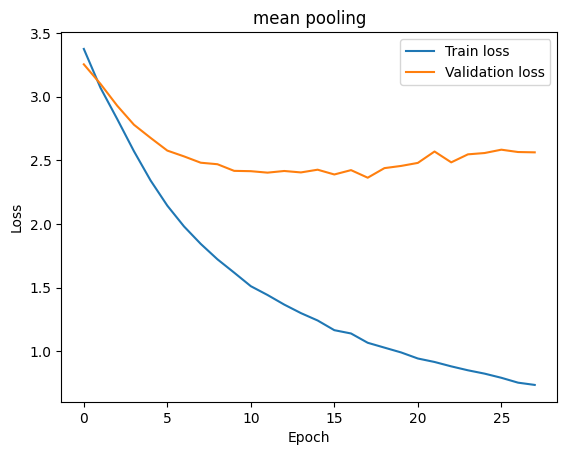

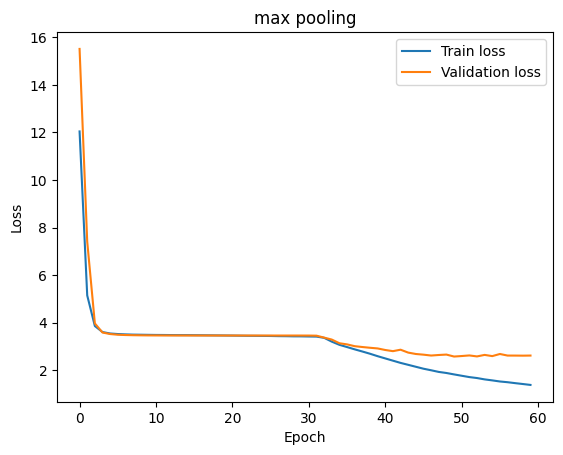

In [18]:
for pooling, folder in models.items():
    with open(f'{folder}/history.json') as f:
        history = json.load(f)

    plt.plot(history['train_loss'], label='Train loss')
    plt.plot(history['val_loss'], label='Validation loss')
    plt.title(f'{pooling} pooling')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

Attention in the last layer of the query encoder with cls pooling, for one question from the FiQA validation set, averaged over the four heads.

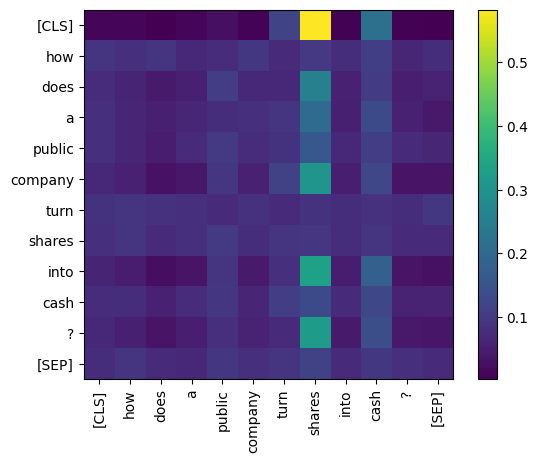

In [ ]:
question = val_queries[44].getQuery()
ids = tokenize([question], 64).to(device)
encoder = dpr['cls'].query_encoder

# "Catch" with a hook the attention weights from the last layer from the encoder
attention = {}
hook = encoder.layers[-1].attention.register_forward_hook(lambda module, inputs, output: attention.update(weights=output[1]))
with torch.no_grad():
    encoder(ids)
hook.remove()

n = int((ids[0] != 0).sum())                                   # number of real tokens
tokens = tokenizer.convert_ids_to_tokens(ids[0][:n].tolist())  # token ids back to words
weights = attention['weights'][0, :, :n, :n].mean(0).cpu()     # average over the heads just the real 

plt.imshow(weights)
plt.xticks(range(n), tokens, rotation=90)
plt.yticks(range(n), tokens)
plt.colorbar()
plt.show()